# Hybrid K-Means & Logistic Regression Classification
**Dataset:** MAGIC Gamma Telescope (`fetch_ucirepo(id=159)`)

This notebook implements an enhanced machine learning pipeline that combines unsupervised clustering (**K-Means**) with supervised classification (**Logistic Regression**).

# Packages

In [44]:
# Install required dependencies
%pip install -q ucimlrepo scikit-learn matplotlib seaborn pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [45]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

# Load Data

In [46]:
# Load MAGIC Gamma Telescope Dataset
magic_gamma_telescope = fetch_ucirepo(id=159)

# Extract features and targets as dataframes
X = magic_gamma_telescope.data.features
y = magic_gamma_telescope.data.targets

# Encode target binary: 'g' (gamma signal) = 1, 'h' (hadron background) = 0
y_numeric = y.iloc[:, 0].map({'g': 1, 'h': 0})
y_numeric.value_counts()

class
1    12332
0     6688
Name: count, dtype: int64

# Train/Test Split (Before Scaling/Clustering)

In [47]:
# stratify=y_numeric - ensures the proportion of classes in both the training and testing sets is the same as in original dataset
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y_numeric, test_size=0.20, random_state=412, stratify=y_numeric)

# Normalization

In [48]:
# K-Means is distance-based, so features need to be on the same scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Convert back to DataFrames for easier handling
X_train_df = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train_raw.index)
X_test_df = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test_raw.index)

# Elbow Method to Pick K

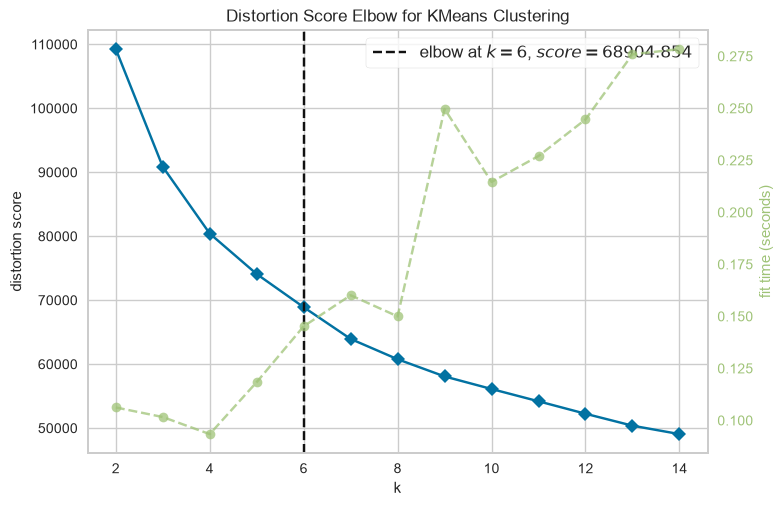

Optimal number of clusters: 6


In [49]:
# Use the training data to determine the optimal number of clusters
model_elbow = KMeans(random_state=412, n_init=10)
visualizer_elbow = KElbowVisualizer(model_elbow, k=(2,15), force_model=True)
visualizer_elbow.fit(X_train_scaled)
visualizer_elbow.show()
optimal_k = visualizer_elbow.elbow_value_
print(f"Optimal number of clusters: {optimal_k}")

# K-Means Clustering Model

In [50]:
# Fit the final K-Means model with the optimal number of clusters
final_kmeans = KMeans(n_clusters=optimal_k, random_state=412, n_init=10)

# Fit on train, predict on both
train_clusters = final_kmeans.fit_predict(X_train_scaled)
test_clusters = final_kmeans.predict(X_test_scaled)

In [51]:
# Add cluster labels to dataframes
X_train_df['cluster'] = train_clusters
X_test_df['cluster'] = test_clusters

# Baseline Evaluation (Overall Logistic Regression)

In [52]:
# Standard logistic regression on the entire training set
baseline_model = LogisticRegression()
baseline_model.fit(X_train_df.drop('cluster', axis=1), y_train)
baseline_probs = baseline_model.predict_proba(X_test_df.drop('cluster', axis=1))[:, 1]

# Hybrid Evaluation (Localized Logistic Regressions)

In [53]:
# Initialize an array for predictions
hybrid_probs = np.zeros(len(X_test_df))
for i in range(optimal_k):
    # Subset data for the specific cluster
    c_train_X = X_train_df[X_train_df['cluster'] == i].drop('cluster', axis=1)
    c_train_y = y_train.loc[c_train_X.index]
    c_test_X = X_test_df[X_test_df['cluster'] == i].drop('cluster', axis=1)
    # Check if cluster has data and more than one class
    if not c_test_X.empty: #If no one in the test set belongs to this cluster, there's no need to predict anything
        if len(np.unique(c_train_y)) > 1:
            local_mdl = LogisticRegression().fit(c_train_X, c_train_y)
            hybrid_probs[X_test_df['cluster'] == i] = local_mdl.predict_proba(c_test_X)[:, 1]
        else: #L ogistic Regression model needs at least two classes to learn
            # If cluster is pure, predict the majority class probability
            hybrid_probs[X_test_df['cluster'] == i] = c_train_y.iloc[0]

# Metrics

In [54]:
# Evaluate the performance of both models using AUC
auc_base = roc_auc_score(y_test, baseline_probs)
auc_hyb = roc_auc_score(y_test, hybrid_probs)
print(f"Baseline AUC: {auc_base:.4f}")
print(f"Hybrid AUC:   {auc_hyb:.4f}")

Baseline AUC: 0.8432
Hybrid AUC:   0.9025


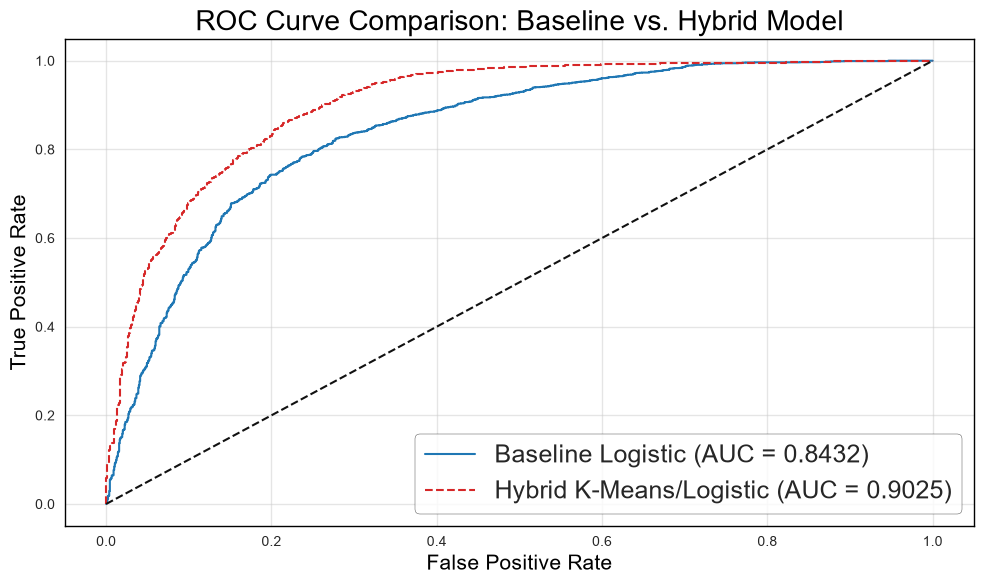

In [55]:
# Generate ROC curves for both models
fpr_base, tpr_base, _ = roc_curve(y_test, baseline_probs)
fpr_hyb, tpr_hyb, _ = roc_curve(y_test, hybrid_probs)

# Plotting the ROC curves
plt.figure(figsize=(10, 6))
plt.plot(fpr_base, tpr_base, color='tab:blue', lw=1.5, label=f'Baseline Logistic (AUC = {auc_base:.4f})')
plt.plot(fpr_hyb, tpr_hyb, color='tab:red', lw=1.5, linestyle='--', label=f'Hybrid K-Means/Logistic (AUC = {auc_hyb:.4f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
plt.legend(loc="lower right", frameon=True, edgecolor='black', fontsize=18)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1)
plt.title('ROC Curve Comparison: Baseline vs. Hybrid Model', fontsize=20, color='black')
plt.xlabel('False Positive Rate', fontsize=15, color='black')
plt.ylabel('True Positive Rate', fontsize=15, color='black')
plt.grid(True, linestyle='-', alpha=0.5)
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.tight_layout()
plt.show()

# Feature Scaling Improve or Complicate the Model Accuracy

In [56]:
# Evaluate the performance of the hybrid model on different values of k
# Function for data and k-values
def evaluate_hybrid(X_tr, X_te, y_tr, y_te, k):
    # K-Means clustering
    kmeans = KMeans(n_clusters=k, random_state=412, n_init=10)
    tr_clusters = kmeans.fit_predict(X_tr)
    te_clusters = kmeans.predict(X_te)

    # Prepare temporary DataFrames for indexing
    tmp_tr = pd.DataFrame(X_tr, index=y_tr.index)
    tmp_te = pd.DataFrame(X_te, index=y_te.index)
    tmp_tr['cluster'] = tr_clusters
    tmp_te['cluster'] = te_clusters

    # Hybrid Evaluation
    hybrid_probs = np.zeros(len(tmp_te))
    for i in range(k):
        c_train_X = tmp_tr[tmp_tr['cluster'] == i].drop('cluster', axis=1)
        c_train_y = y_tr.loc[c_train_X.index]
        c_test_X = tmp_te[tmp_te['cluster'] == i].drop('cluster', axis=1)
        if not c_test_X.empty:
            if len(np.unique(c_train_y)) > 1:
                local_mdl = LogisticRegression(max_iter=1000).fit(c_train_X, c_train_y)
                hybrid_probs[tmp_te['cluster'] == i] = local_mdl.predict_proba(c_test_X)[:, 1]
            else:
                hybrid_probs[tmp_te['cluster'] == i] = c_train_y.iloc[0]
    return roc_auc_score(y_te, hybrid_probs)

results = []
print(f"{'k':<5} | {'Unscaled AUC':<15} | {'Scaled AUC':<15}")
print("-" * 40)

# Evaluate for k from 1 to 25
for k in range(1, 26):
    auc_unscaled = evaluate_hybrid(X_train_raw, X_test_raw, y_train, y_test, k)
    auc_scaled = evaluate_hybrid(X_train_df, X_test_df, y_train, y_test, k)

    results.append((k, auc_unscaled, auc_scaled))
    print(f"{k:<5} | {auc_unscaled:<15.4f} | {auc_scaled:<15.4f}")

k     | Unscaled AUC    | Scaled AUC     
----------------------------------------
1     | 0.8427          | 0.8432         
2     | 0.8601          | 0.8954         
3     | 0.8714          | 0.8937         
4     | 0.8754          | 0.9024         
5     | 0.8854          | 0.9030         
6     | 0.8847          | 0.9025         
7     | 0.8849          | 0.9040         
8     | 0.8831          | 0.9046         
9     | 0.8839          | 0.9073         
10    | 0.8855          | 0.9073         
11    | 0.8848          | 0.9075         
12    | 0.8888          | 0.9088         
13    | 0.8935          | 0.9091         
14    | 0.8932          | 0.9085         
15    | 0.8907          | 0.9085         
16    | 0.8916          | 0.9091         
17    | 0.8926          | 0.9086         
18    | 0.8913          | 0.9087         
19    | 0.8907          | 0.9097         
20    | 0.8890          | 0.9086         
21    | 0.8948          | 0.9089         
22    | 0.8908          | 0.9118   